In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("Titanic-Dataset.csv")

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
# Check missing values in each column

df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
# Calculate percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [8]:
# Fill Age missing values using median

df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill Embarked missing values using mode

df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Fill Fare missing values using median

df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Drop Cabin column due to excessive missing values

df = df.drop('Cabin', axis=1)

print("Missing values handled successfully!")

Missing values handled successfully!


In [9]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [10]:
# Apply Label Encoding on Sex column

le = LabelEncoder()

df['Sex_Encoded'] = le.fit_transform(df['Sex'])

print("Label Encoding completed!")

df[['Sex', 'Sex_Encoded']].head()

Label Encoding completed!


,Sex,Sex_Encoded
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1


In [11]:
# Apply One-Hot Encoding on Embarked column

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded_data = ohe.fit_transform(df[['Embarked']])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=ohe.get_feature_names_out(['Embarked']),
    index=df.index
)

# Add encoded columns to original dataset

df = pd.concat([df, encoded_df], axis=1)

print("One-Hot Encoding completed!")

df.head()

One-Hot Encoding completed!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Sex_Encoded,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,1,0.0,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,0,1.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,0,0.0,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,1,0.0,0.0,1.0


In [12]:
print("Updated Dataset Columns:")

print(df.columns)

Updated Dataset Columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked', 'Sex_Encoded', 'Embarked_C',
       'Embarked_Q', 'Embarked_S'],
      dtype='str')


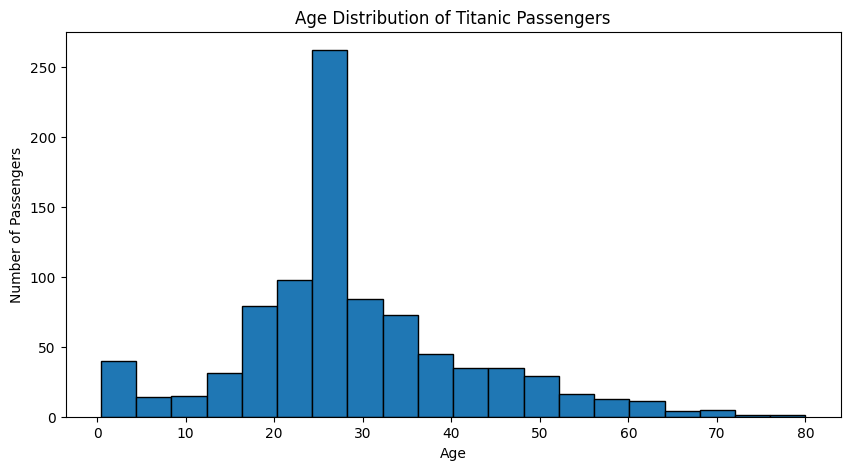

In [13]:
# Visualize Age Distribution using Matplotlib

plt.figure(figsize=(10, 5))

plt.hist(df['Age'], bins=20, edgecolor='black')

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

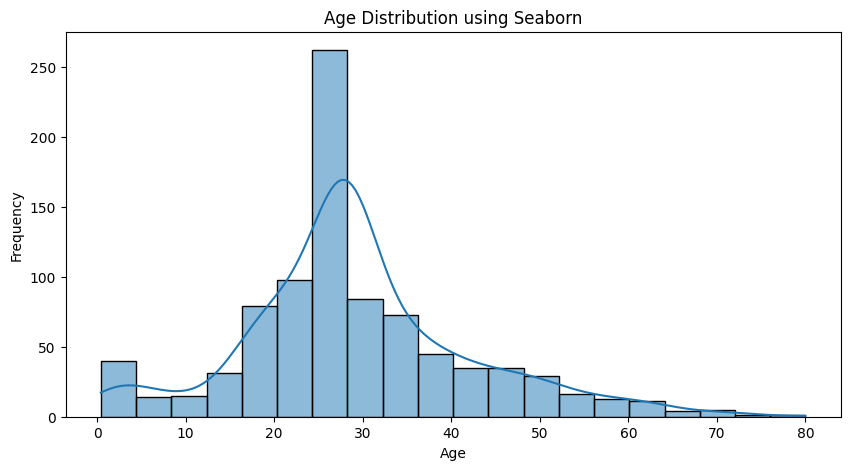

In [14]:
# Visualize Age Distribution using Seaborn

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Age', bins=20, kde=True)

plt.title('Age Distribution using Seaborn')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

In [15]:
print("Minimum Age:", df['Age'].min())

print("Maximum Age:", df['Age'].max())

print("Average Age:", df['Age'].mean())

print("Median Age:", df['Age'].median())

Minimum Age: 0.42
Maximum Age: 80.0
Average Age: 29.36158249158249
Median Age: 28.0


In [16]:
# Export cleaned dataset

df.to_csv('cleaned_titanic.csv', index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
